In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [ ]:
df=pd.read_csv('/content/Student_Performance.csv')

In [ ]:
df.shape

(25000, 16)

In [ ]:
df.head()

,student_id,age,gender,school_type,parent_education,study_hours,attendance_percentage,internet_access,travel_time,extra_activities,study_method,math_score,science_score,english_score,overall_score,final_grade
0,1,14,male,public,post graduate,3.1,84.3,yes,<15 min,yes,notes,42.7,55.4,57.0,53.1,e
1,2,18,female,public,graduate,3.7,87.8,yes,>60 min,no,textbook,57.6,68.8,64.8,61.3,d
2,3,17,female,private,post graduate,7.9,65.5,no,<15 min,no,notes,84.8,95.0,79.2,89.6,b
3,4,16,other,public,high school,1.1,58.1,no,15-30 min,no,notes,44.4,27.5,54.7,41.6,e
4,5,16,female,public,high school,1.3,61.0,yes,30-60 min,yes,group study,8.9,32.7,30.0,25.4,f


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             25000 non-null  int64  
 1   age                    25000 non-null  int64  
 2   gender                 25000 non-null  object 
 3   school_type            25000 non-null  object 
 4   parent_education       25000 non-null  object 
 5   study_hours            25000 non-null  float64
 6   attendance_percentage  25000 non-null  float64
 7   internet_access        25000 non-null  object 
 8   travel_time            25000 non-null  object 
 9   extra_activities       25000 non-null  object 
 10  study_method           25000 non-null  object 
 11  math_score             25000 non-null  float64
 12  science_score          25000 non-null  float64
 13  english_score          25000 non-null  float64
 14  overall_score          25000 non-null  float64
 15  fi

In [ ]:
df.isnull().sum()

,0
student_id,0
age,0
gender,0
school_type,0
parent_education,0
study_hours,0
attendance_percentage,0
internet_access,0
travel_time,0
extra_activities,0


In [ ]:
df.duplicated().sum()

np.int64(10000)

In [ ]:
df['student_id'].duplicated().sum()

np.int64(10000)

In [ ]:
df[df['student_id'].duplicated(keep=False)].sort_values('student_id')

,student_id,age,gender,school_type,parent_education,study_hours,attendance_percentage,internet_access,travel_time,extra_activities,study_method,math_score,science_score,english_score,overall_score,final_grade
17372,2,18,female,public,graduate,3.7,87.8,yes,>60 min,no,textbook,57.6,68.8,64.8,61.3,d
17524,2,18,female,public,graduate,3.7,87.8,yes,>60 min,no,textbook,57.6,68.8,64.8,61.3,d
23867,2,18,female,public,graduate,3.7,87.8,yes,>60 min,no,textbook,57.6,68.8,64.8,61.3,d
1,2,18,female,public,graduate,3.7,87.8,yes,>60 min,no,textbook,57.6,68.8,64.8,61.3,d
2,3,17,female,private,post graduate,7.9,65.5,no,<15 min,no,notes,84.8,95.0,79.2,89.6,b
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24148,14997,17,other,private,diploma,6.7,63.5,no,<15 min,yes,mixed,84.4,67.2,96.2,78.8,c
14997,14998,17,male,private,phd,5.2,58.2,yes,30-60 min,no,group study,69.0,57.2,74.1,64.3,d
23205,14998,17,male,private,phd,5.2,58.2,yes,30-60 min,no,group study,69.0,57.2,74.1,64.3,d
23588,14999,16,other,private,graduate,1.0,68.7,yes,30-60 min,yes,textbook,24.2,41.4,30.5,33.6,f


In [ ]:
df_clean=df.drop_duplicates().copy()

In [ ]:
df_clean.shape

(15000, 16)

In [ ]:
df_clean.isnull().sum()

,0
student_id,0
age,0
gender,0
school_type,0
parent_education,0
study_hours,0
attendance_percentage,0
internet_access,0
travel_time,0
extra_activities,0


In [ ]:
print("Age outside expected dataset range:")
print(df_clean[~df_clean['age'].between(14, 19)])

print("Invalid attendance:")
print(df_clean[
    ~df_clean['attendance_percentage'].between(0, 100)
])

score_columns = [
    'math_score',
    'science_score',
    'english_score',
    'overall_score'
]

for col in score_columns:
    print(col, df_clean[
        ~df_clean[col].between(0, 100)
    ].shape[0])

Age outside expected dataset range:
Empty DataFrame
Columns: [student_id, age, gender, school_type, parent_education, study_hours, attendance_percentage, internet_access, travel_time, extra_activities, study_method, math_score, science_score, english_score, overall_score, final_grade]
Index: []
Invalid attendance:
Empty DataFrame
Columns: [student_id, age, gender, school_type, parent_education, study_hours, attendance_percentage, internet_access, travel_time, extra_activities, study_method, math_score, science_score, english_score, overall_score, final_grade]
Index: []
math_score 0
science_score 0
english_score 0
overall_score 0


In [ ]:
df_clean.to_csv(
    "Student_Performance_Cleaned.csv",
    index=False
)

Exploratory Data Analysis

In [ ]:
df_clean.head()

,student_id,age,gender,school_type,parent_education,study_hours,attendance_percentage,internet_access,travel_time,extra_activities,study_method,math_score,science_score,english_score,overall_score,final_grade
0,1,14,male,public,post graduate,3.1,84.3,yes,<15 min,yes,notes,42.7,55.4,57.0,53.1,e
1,2,18,female,public,graduate,3.7,87.8,yes,>60 min,no,textbook,57.6,68.8,64.8,61.3,d
2,3,17,female,private,post graduate,7.9,65.5,no,<15 min,no,notes,84.8,95.0,79.2,89.6,b
3,4,16,other,public,high school,1.1,58.1,no,15-30 min,no,notes,44.4,27.5,54.7,41.6,e
4,5,16,female,public,high school,1.3,61.0,yes,30-60 min,yes,group study,8.9,32.7,30.0,25.4,f


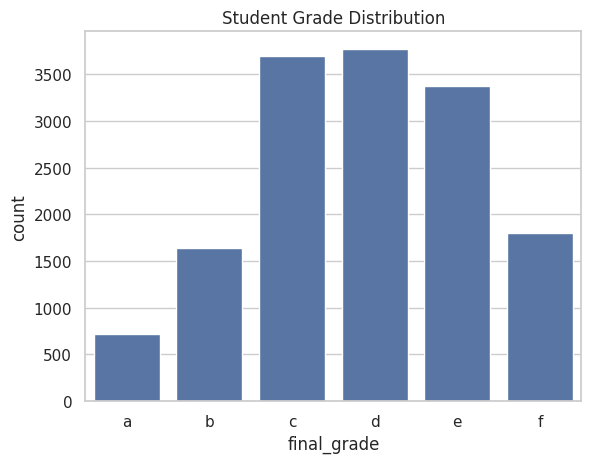

In [ ]:
sns.countplot(
    data=df_clean,
    x='final_grade',
    order=['a','b','c','d','e','f']
)

plt.title("Student Grade Distribution")
plt.show()

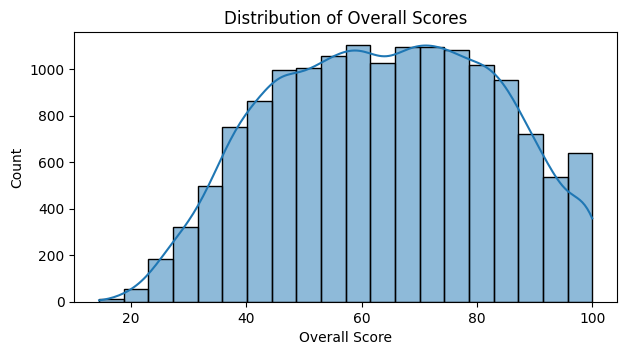

In [ ]:
plt.figure(figsize=(7,3.5))

sns.histplot(
    data=df_clean,
    x='overall_score',
    bins=20,
    kde=True
)

plt.title("Distribution of Overall Scores")
plt.xlabel("Overall Score")
plt.show()

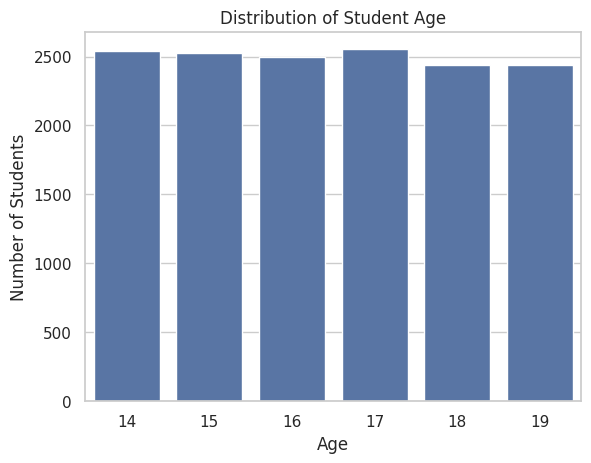

In [ ]:
sns.countplot(data=df_clean, x='age')

plt.title("Distribution of Student Age")
plt.xlabel("Age")
plt.ylabel("Number of Students")
df_clean['age'].value_counts()
plt.show()

In [ ]:
df_top_1000=df_clean.head(1000)

Does study time relate to performance?

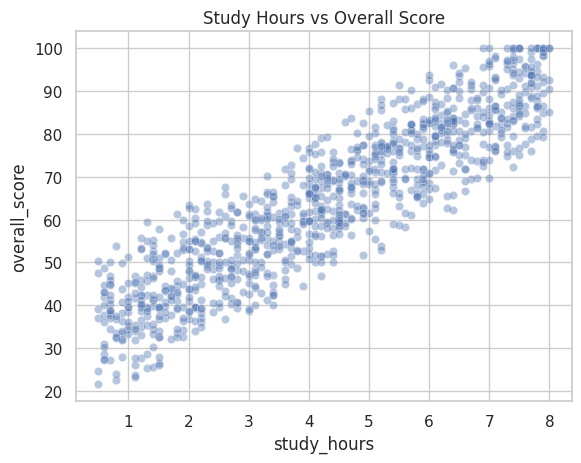

In [ ]:
sns.scatterplot(
    data=df_top_1000,
    x='study_hours',
    y='overall_score',
    alpha=0.4
)

plt.title("Study Hours vs Overall Score")
plt.show()

Does attendance relate to performance?

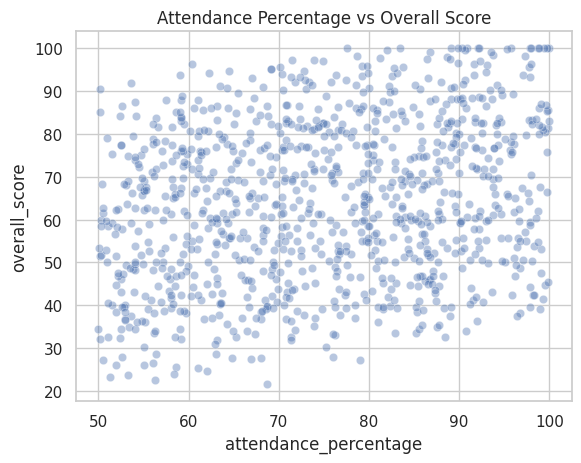

In [ ]:
sns.scatterplot(
    data=df_top_1000,
    x='attendance_percentage',
    y='overall_score',
    alpha=0.4
)

plt.title("Attendance Percentage vs Overall Score")
plt.show()


Which study method has the highest average score?

In [ ]:
study_analysis=df_clean.groupby('study_method')['overall_score'].mean().reset_index()
study_analysis

,study_method,overall_score
0,coaching,64.476259
1,group study,63.251287
2,mixed,63.653574
3,notes,63.858012
4,online videos,64.683063
5,textbook,64.190024


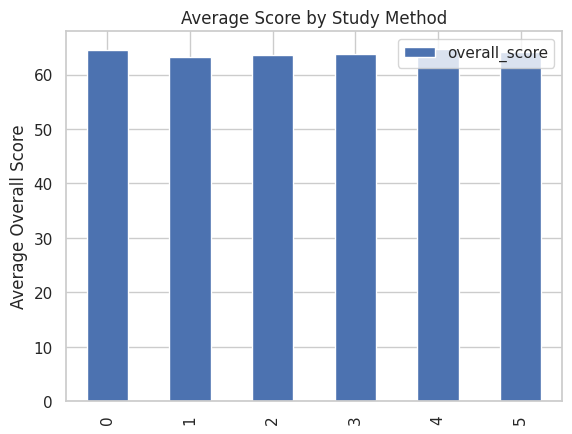

In [ ]:
study_analysis.plot(kind='bar')

plt.title("Average Score by Study Method")
plt.ylabel("Average Overall Score")
plt.show()

Investigate whether different student groups show different average performance.

In [ ]:
school_analysis=df_clean.groupby('school_type')['overall_score'].agg('mean','median','mode').reset_index()
school_analysis

,school_type,overall_score
0,private,64.036365
1,public,63.994145


Correlation analysis

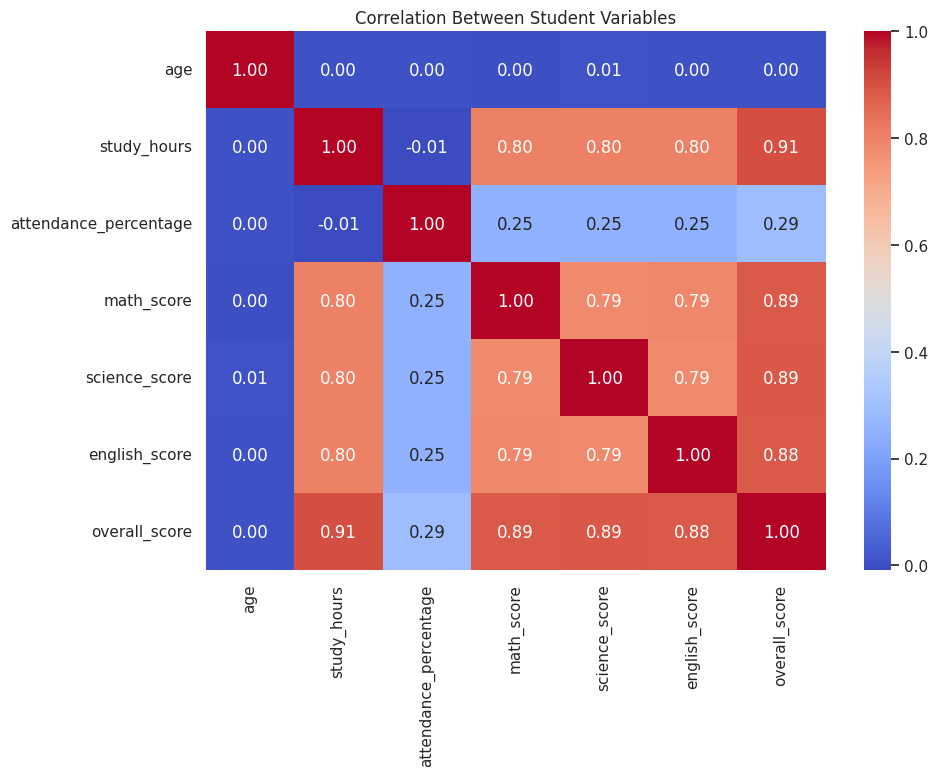

In [ ]:
numeric_columns = [
    'age',
    'study_hours',
    'attendance_percentage',
    'math_score',
    'science_score',
    'english_score',
    'overall_score'
]

correlation = df_clean[numeric_columns].corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Student Variables")
plt.show()

Statistical analysis and hypothesis testing

Study hours and overall performance

In [ ]:
r, p_value = stats.pearsonr(
    df_clean['study_hours'],
    df_clean['overall_score']
)

print("Correlation:", r)
print("P-value:", p_value)

if p_value < 0.05:
    print("Statistically significant association")
else:
    print("Insufficient evidence of an association")

Correlation: 0.9058848411126499
P-value: 0.0
Statistically significant association


Attendance and overall performance

In [ ]:
r, p_value = stats.pearsonr(
    df_clean['attendance_percentage'],
    df_clean['overall_score']
)

print("Correlation:", r)
print("P-value:", p_value)

Correlation: 0.28847322776538425
P-value: 2.4607161278292517e-285


Does performance differ by study method?

In [ ]:
groups = [
    group['overall_score'].values
    for name, group in df_clean.groupby('study_method')
]

statistic, p_value = stats.kruskal(*groups)

print("Test statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("At least one study method group differs")
else:
    print("Insufficient evidence of a difference")

Test statistic: 10.204621078817448
P-value: 0.06964071277444024
Insufficient evidence of a difference


Create the risk category

In [ ]:
df_clean['academic_risk'] = np.where(
    df_clean['final_grade'].isin(['e', 'f']),
    'At Risk',
    'Not At Risk'
)

print(df_clean['academic_risk'].value_counts())

academic_risk
Not At Risk    9826
At Risk        5174
Name: count, dtype: int64


In [ ]:
risk_analysis = df_clean.groupby(
    'academic_risk'
).agg(
    student_count=('student_id', 'count'),
    avg_study_hours=('study_hours', 'mean'),
    avg_attendance=('attendance_percentage', 'mean'),
    avg_score=('overall_score', 'mean')
)

print(risk_analysis.round(2))

               student_count  avg_study_hours  avg_attendance  avg_score
academic_risk                                                           
At Risk                 5174             1.98           71.18      42.79
Not At Risk             9826             5.46           77.00      75.19


Then investigate risk distribution by study method:

In [ ]:
risk_method = pd.crosstab(
    df_clean['study_method'],
    df_clean['academic_risk'],
    normalize='index'
) * 100

print(risk_method.round(2))

academic_risk  At Risk  Not At Risk
study_method                       
coaching         34.15        65.85
group study      35.76        64.24
mixed            35.24        64.76
notes            34.47        65.53
online videos    32.66        67.34
textbook         34.64        65.36


In [ ]:
risk_school = pd.crosstab(
    df_clean['school_type'],
    df_clean['academic_risk'],
    normalize='index'
) * 100

print(risk_school.round(2))

academic_risk  At Risk  Not At Risk
school_type                        
private          34.31        65.69
public           34.68        65.32
